In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")

train = pd.read_csv(
    "derived/train_cleaned_enriched.csv"
)

test = pd.read_csv(
    "derived/test_cleaned_enriched.csv"
)

print("Training dataset:", train.shape)
print("Test dataset:", test.shape)

Training dataset: (149841, 21)
Test dataset: (50000, 20)


In [4]:
TARGET = "MONTHLY_RENT"

approval_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"])

cutoff = (
    approval_dates.max().to_period("M").start_time
    - pd.DateOffset(months=12)
)

is_validation = approval_dates > cutoff

training_data = train.loc[~is_validation].copy()
validation_data = train.loc[is_validation].copy()

print("Training:", training_data.shape)
print("Validation:", validation_data.shape)

print("Training period:",
      training_data["RENT_APPROVAL_DATE"].min(),
      "to",
      training_data["RENT_APPROVAL_DATE"].max())

print("Validation period:",
      validation_data["RENT_APPROVAL_DATE"].min(),
      "to",
      validation_data["RENT_APPROVAL_DATE"].max())

Training: (114683, 21)
Validation: (35158, 21)
Training period: 2021-01-01 to 2024-03-01
Validation period: 2024-04-01 to 2025-03-01


In [5]:
CATBOOST_ALL_FEATURES = [
    "FLOOR_AREA_SQM",
    "LEASE_COMMENCE_DATE",
    "HDB_LATITUDE",
    "HDB_LONGITUDE",
    "HDB_YEAR_COMPLETED",
    "NEAREST_MRT_KM",
    "NEAREST_SCHOOL_KM",
    "NEAREST_MALL_KM",
    "APPROVAL_YEAR",
    "APPROVAL_MONTH",
    "MONTH_INDEX",
    "BUILDING_AGE",
    "TOWN",
    "FLAT_TYPE",
    "FLAT_MODEL",
    "HDB_PLANNING_AREA",
    "LOCATION_KEY"
]

CATBOOST_CATEGORICAL = [
    "TOWN",
    "FLAT_TYPE",
    "FLAT_MODEL",
    "HDB_PLANNING_AREA",
    "LOCATION_KEY"
]

X_train = training_data[CATBOOST_ALL_FEATURES].copy()
y_train = training_data[TARGET].copy()

X_val = validation_data[CATBOOST_ALL_FEATURES].copy()
y_val = validation_data[TARGET].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

Training features: (114683, 17)
Validation features: (35158, 17)


In [6]:
CB_PARAMS = dict(
    loss_function="RMSE",
    eval_metric="RMSE",
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=5,
    random_seed=42,
    thread_count=4,
    allow_writing_files=False
)

baseline_model = CatBoostRegressor(
    iterations=2000,
    **CB_PARAMS
)

baseline_model.fit(
    X_train,
    y_train,
    cat_features=CATBOOST_CATEGORICAL,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200
)

0:	learn: 713.6667349	test: 823.7971396	best: 823.7971396 (0)	total: 77.5ms	remaining: 2m 34s
200:	learn: 480.6078977	test: 480.2013346	best: 480.2013346 (200)	total: 3.26s	remaining: 29.2s
400:	learn: 476.7296341	test: 476.2264313	best: 476.2206885 (391)	total: 6.4s	remaining: 25.5s
600:	learn: 474.0167548	test: 474.3569810	best: 474.3569810 (600)	total: 9.71s	remaining: 22.6s
800:	learn: 471.7140243	test: 473.3727622	best: 473.3727622 (800)	total: 13s	remaining: 19.5s
1000:	learn: 469.9135725	test: 472.8689593	best: 472.8663302 (999)	total: 16.6s	remaining: 16.5s
1200:	learn: 468.1532489	test: 472.2552763	best: 472.2552763 (1200)	total: 19.9s	remaining: 13.3s
1400:	learn: 466.6862347	test: 471.9540223	best: 471.9540223 (1400)	total: 23.3s	remaining: 9.96s
1600:	learn: 465.2165645	test: 471.7173115	best: 471.7173115 (1600)	total: 26.9s	remaining: 6.7s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 471.701336
bestIteration = 1615

Shrink model to first 1616 iteratio

CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='RMSE', iterations=2000, l2_leaf_reg=5, learning_rate=0.05, loss_function='RMSE', random_seed=42, thread_count=4)

In [7]:
baseline_predictions = baseline_model.predict(X_val)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_predictions)
)

baseline_mae = mean_absolute_error(
    y_val, baseline_predictions
)

baseline_r2 = r2_score(
    y_val, baseline_predictions
)

print("BASELINE RESULTS")
print("----------------")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"MAE:  {baseline_mae:.4f}")
print(f"R2:   {baseline_r2:.4f}")
print("Best iterations:", baseline_model.tree_count_)

BASELINE RESULTS
----------------
RMSE: 471.7013
MAE:  349.0779
R2:   0.4880
Best iterations: 1616


<h1>Experiment	Features removed</h1>


All other features remain unchanged in each experiment.


| Experiments | Features removed |
| :- | :-: | 
| Baseline | None |
| A1 | TOWN, LOCATION_KEY |
| A2 | FLAT_TYPE |
| A3 | FLAT_MODEL |
| A4 | FLOOR_AREA_SQM |
| A5 | LEASE_COMMENCE_DATE, BUILDING_AGE |
| A6 | APPROVAL_YEAR, APPROVAL_MONTH, MONTH_INDEX |


In [ ]:
# Original rental features to remove
ABLATION_GROUPS = {
    "Without Location": [
        "TOWN",
        "LOCATION_KEY"
    ],

    "Without Flat Type": [
        "FLAT_TYPE"
    ],

    "Without Flat Model": [
        "FLAT_MODEL"
    ],

    "Without Floor Area": [
        "FLOOR_AREA_SQM"
    ],

    "Without Lease Commencement": [
        "LEASE_COMMENCE_DATE",
        "BUILDING_AGE"
    ],

    "Without Approval Date Features": [
        "APPROVAL_YEAR",
    "APPROVAL_MONTH",
    "MONTH_INDEX",
    "BUILDING_AGE"
    ]
}


AUXILIARY_FEATURES = [
    "HDB_LATITUDE",
    "HDB_LONGITUDE",
    "HDB_YEAR_COMPLETED",
    "NEAREST_MRT_KM",
    "NEAREST_SCHOOL_KM",
    "NEAREST_MALL_KM",
    "HDB_PLANNING_AREA"
]

print("Baseline feature count:", len(CATBOOST_ALL_FEATURES))
print("Auxiliary feature count:", len(AUXILIARY_FEATURES))

for name, removed_features in ABLATION_GROUPS.items():
    print(f"\n{name}:")
    print("Removed:", removed_features)

Baseline feature count: 17
Auxiliary feature count: 7

Without Location:
Removed: ['TOWN', 'LOCATION_KEY']

Without Flat Type:
Removed: ['FLAT_TYPE']

Without Flat Model:
Removed: ['FLAT_MODEL']

Without Floor Area:
Removed: ['FLOOR_AREA_SQM']

Without Lease Commencement:
Removed: ['LEASE_COMMENCE_DATE', 'BUILDING_AGE']

Without Approval Date Features:
Removed: ['APPROVAL_YEAR', 'APPROVAL_MONTH', 'MONTH_INDEX', 'BUILDING_AGE']


BUILDING_AGE is derived from both APPROVAL_YEAR and LEASE_COMMENCE_DATE. If we remove the approval-date features but retain BUILDING_AGE, the model still receives information derived from the approval year.

So included BUILDING_AGE in the approval-date ablation as well. This makes that experiment more meaningful.

In [ ]:
def run_ablation_experiment(experiment_name, removed_features):

    # Select remaining features
    selected_features = [
        col for col in CATBOOST_ALL_FEATURES
        if col not in removed_features
    ]

    # auxiliary features are retained
    assert all(
        col in selected_features
        for col in AUXILIARY_FEATURES
    ), "An auxiliary feature was accidentally removed!"

    
    X_train_exp = training_data[selected_features].copy()
    X_val_exp = validation_data[selected_features].copy()

    y_train_exp = training_data[TARGET]
    y_val_exp = validation_data[TARGET]

    # Retain categorical features still present
    categorical_features = [
        col for col in CATBOOST_CATEGORICAL
        if col in selected_features
    ]

    # Create model using the same configuration
    model = CatBoostRegressor(
        iterations=2000,
        **CB_PARAMS
    )

    print(f"\nRunning: {experiment_name}")
    print("Number of features:", len(selected_features))

    
    model.fit(
        X_train_exp,
        y_train_exp,
        cat_features=categorical_features,
        eval_set=(X_val_exp, y_val_exp),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False
    )

    
    predictions = model.predict(X_val_exp)

    
    rmse = np.sqrt(
        mean_squared_error(y_val_exp, predictions)
    )

    mae = mean_absolute_error(y_val_exp, predictions)
    r2 = r2_score(y_val_exp, predictions)

    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R2: {r2:.4f}")
    print("Best trees:", model.tree_count_)

    return {
        "Experiment": experiment_name,
        "Removed Features": ", ".join(removed_features),
        "Remaining Features": len(selected_features),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Best Trees": model.tree_count_
    }

In [ ]:
ablation_results = []

for experiment_name, removed_features in ABLATION_GROUPS.items():

    result = run_ablation_experiment(
        experiment_name,
        removed_features
    )

    ablation_results.append(result)


ablation_df = pd.DataFrame(ablation_results)

print("\nABLATION STUDY RESULTS")
display(ablation_df)


Running: Without Location
Number of features: 15
RMSE: 476.0108
MAE: 352.7541
R2: 0.4786
Best trees: 1711

Running: Without Flat Type
Number of features: 16
RMSE: 474.1150
MAE: 351.4845
R2: 0.4827
Best trees: 1991

Running: Without Flat Model
Number of features: 16
RMSE: 471.7094
MAE: 349.2771
R2: 0.4880
Best trees: 1976

Running: Without Floor Area
Number of features: 16
RMSE: 471.6907
MAE: 349.1563
R2: 0.4880
Best trees: 1813

Running: Without Lease Commencement
Number of features: 15
RMSE: 471.7125
MAE: 348.9818
R2: 0.4880
Best trees: 1636

Running: Without Approval Date Features
Number of features: 13
RMSE: 715.5879
MAE: 625.8468
R2: -0.1783
Best trees: 1159

ABLATION STUDY RESULTS


,Experiment,Removed Features,Remaining Features,RMSE,MAE,R2,Best Trees
0,Without Location,"TOWN, LOCATION_KEY",15,476.010839,352.754119,0.478589,1711
1,Without Flat Type,FLAT_TYPE,16,474.115010,351.484549,0.482734,1991
2,Without Flat Model,FLAT_MODEL,16,471.709433,349.277121,0.487969,1976
3,Without Floor Area,FLOOR_AREA_SQM,16,471.690683,349.156303,0.488010,1813
4,Without Lease Commencement,"LEASE_COMMENCE_DATE, BUILDING_AGE",15,471.712475,348.981809,0.487963,1636
5,Without Approval Date Features,"APPROVAL_YEAR, APPROVAL_MONTH, MONTH_INDEX, BU...",13,715.587925,625.846798,-0.178346,1159


The model's RMSE increased from 471.70 to 715.59 when we removed the approval-date features and BUILDING_AGE.

That is a rapid decrease in prediction accuracy.

In [18]:
baseline_rmse = 471.701336

plot_df = pd.concat([
    pd.DataFrame({
        "Experiment": ["Baseline"],
        "RMSE": [baseline_rmse]
    }),
    ablation_df[["Experiment", "RMSE"]]
], ignore_index=True)

plot_df["RMSE Change (%)"] = (
    (plot_df["RMSE"] - baseline_rmse) / baseline_rmse
) * 100

display(plot_df.round(3))

,Experiment,RMSE,RMSE Change (%)
0,Baseline,471.701,0.000
1,Without Location,476.011,0.914
2,Without Flat Type,474.115,0.512
3,Without Flat Model,471.709,0.002
4,Without Floor Area,471.691,-0.002
5,Without Lease Commencement,471.712,0.002
6,Without Approval Date Features,715.588,51.704


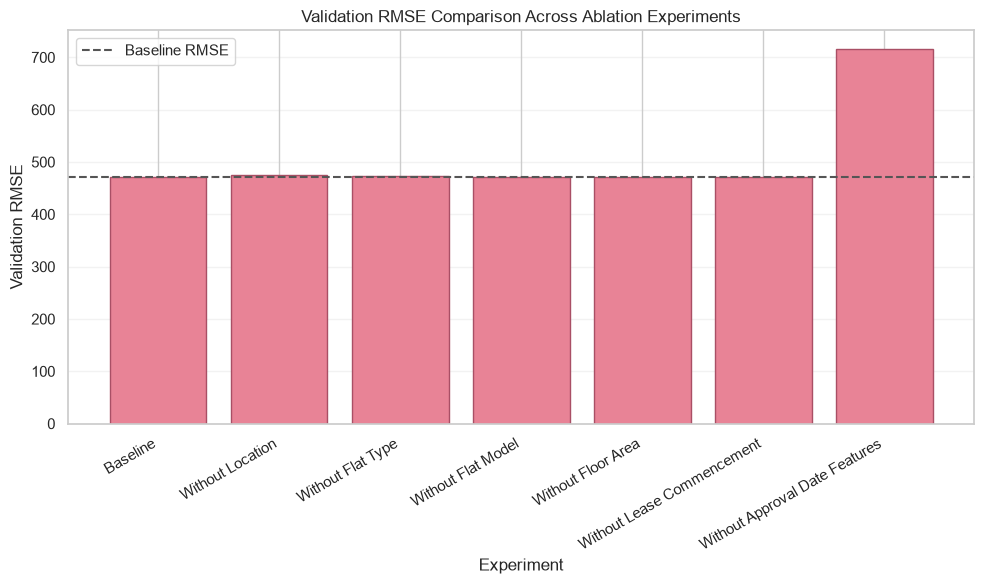

In [20]:
import matplotlib.pyplot as plt

PINK = "#E88396"
EDGE = "#A94F65"

plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["Experiment"],
    plot_df["RMSE"],
    color=PINK,
    edgecolor=EDGE,
    linewidth=1
)

plt.axhline(
    y=baseline_rmse,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label="Baseline RMSE"
)

plt.ylabel("Validation RMSE")
plt.xlabel("Experiment")
plt.title("Validation RMSE Comparison Across Ablation Experiments")

plt.xticks(rotation=30, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig("ablation_rmse_comparison.png",
            dpi=300, bbox_inches="tight")

plt.show()

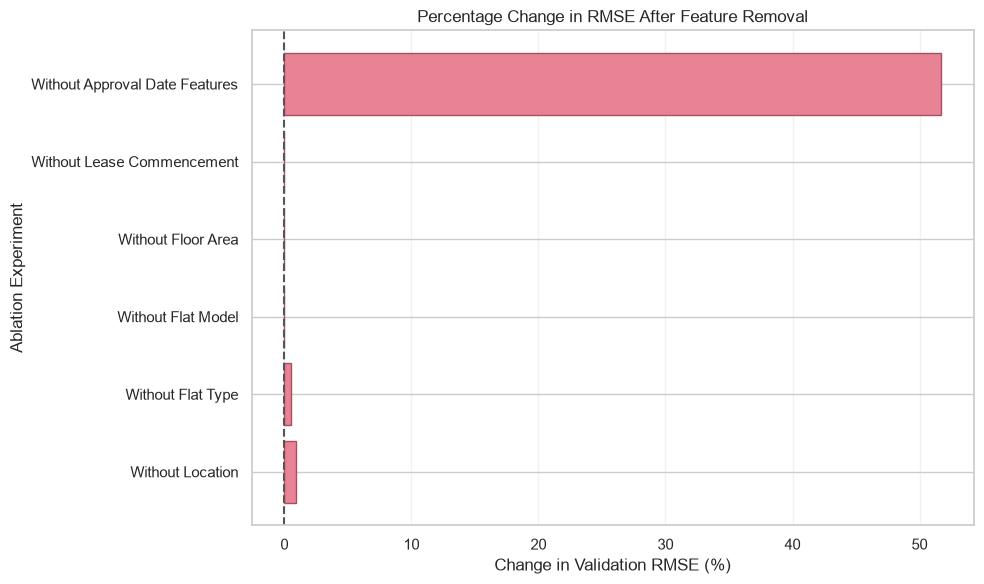

In [21]:
plt.figure(figsize=(10, 6))

ablation_only = plot_df[
    plot_df["Experiment"] != "Baseline"
]

plt.barh(
    ablation_only["Experiment"],
    ablation_only["RMSE Change (%)"],
    color=PINK,
    edgecolor=EDGE,
    linewidth=1
)

plt.axvline(
    x=0,
    color="#555555",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Change in Validation RMSE (%)")
plt.ylabel("Ablation Experiment")
plt.title("Percentage Change in RMSE After Feature Removal")

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig("ablation_rmse_percentage_change.png",
            dpi=300, bbox_inches="tight")

plt.show()